# Dry Bean Variety Classification with Small Neural Networks
**Advanced Deep Learning • Group Mini Project • 16 October 2026**  
**Members:** [PUYOU-BRACQ Edgar / 26/581691/NPA/20031], [Aulia Gita Pratiwi / 25/572701/PPA/07197], [Muhammad Zidan Arsyad / 25/572381/PPA/07192], [Farichaturrifqi Aryanitasari / 25/574224/PPA/07240]

## Question and scope
Can a small multilayer perceptron classify seven dry bean varieties using 16 measured size and shape features? Do depth, learning rate, dropout or class-weighted loss improve validation macro-F1?

We compare six neural configurations across seeds 7, 21 and 42. We also include a prespecified logistic-regression reference. This is **tabular classification using features already extracted from images**, not end-to-end image recognition. It fits the assignment's neural network and/or deep learning requirement without adding an unnecessary CNN.

## Run in Google Colab
Upload this `.ipynb`, connect to a Python CPU runtime, then choose **Runtime > Run all**. CPU is sufficient. The notebook requires no private token, Drive mount or separate source file. It downloads a public dataset on the first run and creates `results/`. The last cell creates a results ZIP. Save the executed notebook to Drive, share view access and paste its actual URL onto slide 11. The delivered notebook contains actual local execution outputs for offline reading. Cross-platform numerical differences are possible.


In [26]:
import importlib.util, subprocess, sys
packages = {'torch':'torch', 'numpy':'numpy', 'pandas':'pandas',
            'matplotlib':'matplotlib', 'sklearn':'scikit-learn', 'scipy':'scipy'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import copy, hashlib, io, json, platform, random, time, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, torch
from scipy.io import arff
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

DEVICE = torch.device('cpu')
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
SEEDS, SPLIT_SEED = [7, 21, 42], 42
MAX_EPOCHS, PATIENCE, BATCH_SIZE = 40, 8, 256
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
versions = {'python':platform.python_version(), 'torch':torch.__version__,
            'numpy':np.__version__, 'pandas':pd.__version__,
            'sklearn':sklearn.__version__, 'scipy':scipy.__version__, 'device':str(DEVICE)}
print(versions)


{'python': '3.12.3', 'torch': '2.6.0+cpu', 'numpy': '1.26.4', 'pandas': '2.2.2', 'sklearn': '1.5.1', 'scipy': '1.13.0', 'device': 'cpu'}


## 1. Public dataset and cleaning
**Dry Bean (2020), UCI Machine Learning Repository**, [DOI: 10.24432/C50S4B](https://doi.org/10.24432/C50S4B), [repository](https://archive.ics.uci.edu/dataset/602/dry+bean). License: **CC BY 4.0**. The repository credits the work of Murat Koklu and Ilker Ali Ozkan on multiclass dry bean classification.

The archive contains 13,611 rows with 16 numeric features and one class label. Features describe size and shape, such as area, perimeter, major/minor axes, aspect ratio and compactness. Labels are BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER and SIRA. The code uses the spellings in the data file, including `AspectRation` and lowercase `roundness`.

We check missing values, numeric ranges and conflicting labels. We remove **exact duplicate rows before splitting** to prevent identical examples entering different partitions. This does not guarantee absence of near-duplicates or dependence between beans from the same acquisition batch. The downloaded files provide no suitable group or time identifier for a grouped split.


In [27]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip'
archive_path = Path('drybean.zip')
if not archive_path.exists():
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        archive_path.write_bytes(response.read())
archive_bytes = archive_path.read_bytes()
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    filename = next(name for name in archive.namelist() if name.endswith('.arff'))
    records, _ = arff.loadarff(io.StringIO(archive.read(filename).decode('utf-8')))
raw = pd.DataFrame(records)
raw['Class'] = raw['Class'].str.decode('utf-8')
features = [column for column in raw.columns if column != 'Class']
assert raw.shape == (13611, 17) and len(features) == 16
assert not raw.isna().any().any()
assert np.isfinite(raw[features].to_numpy()).all()
conflicting = raw.groupby(features, dropna=False)['Class'].nunique().gt(1).sum()
assert conflicting == 0, 'Investigate identical features with different labels before splitting.'
data = raw.drop_duplicates().reset_index(names='source_row')
removed = len(raw) - len(data)
data_hash = hashlib.sha256(archive_bytes).hexdigest()
print('Raw rows:', len(raw), 'Exact duplicates removed:', removed, 'Clean rows:', len(data))
print('Missing values:', int(raw.isna().sum().sum()))
print('Number of features:', len(features))
print('Features:', features)
print('Classes:', data['Class'].value_counts().to_dict())
print('Dataset SHA256:', data_hash)


Raw rows: 13611 Exact duplicates removed: 68 Clean rows: 13543
Missing values: 0
Number of features: 16
Features: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Classes: {'DERMASON': 3546, 'SIRA': 2636, 'SEKER': 2027, 'HOROZ': 1860, 'CALI': 1630, 'BARBUNYA': 1322, 'BOMBAY': 522}
Dataset SHA256: 0a64eff5be87f48c3dbbfc0a12a56c5d5b5167ef8e61cd45d69b3e7c7130c06f


In [28]:
data.head()

,source_row,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Stratified train / validation / test split
We allocate approximately **70% training, 15% validation and 15% test**, preserving class proportions with stratification. Rounding can make counts differ by one. Training updates weights, validation selects checkpoints and configurations, and test evaluates the frozen choice. We use one fixed holdout split rather than k-fold validation for clarity and runtime. Three training seeds are **not three folds**.

Fit `StandardScaler` **only on training features**, then apply the same training mean and standard deviation to validation and test. This is important because area and shape ratios have very different numerical scales. Standardization computes `(x − training mean) / training standard deviation`. Do not fit the scaler on all rows.

Classes have unequal counts, so **macro-F1 is the primary configuration-selection metric**. It gives each class equal weight. We also report accuracy and per-class metrics. One experiment tests class-weighted training loss, with weights computed only from training labels. We do not oversample or use SMOTE.


   class  train  validation  test
BARBUNYA    925         199   198
  BOMBAY    366          78    78
    CALI   1141         244   245
DERMASON   2482         532   532
   HOROZ   1302         279   279
   SEKER   1419         304   304
    SIRA   1845         395   396
Split totals: 9480 2031 2032
Class weights: {'BARBUNYA': 1.4639999866485596, 'BOMBAY': 3.700000047683716, 'CALI': 1.187000036239624, 'DERMASON': 0.5460000038146973, 'HOROZ': 1.0399999618530273, 'SEKER': 0.9539999961853027, 'SIRA': 0.734000027179718}


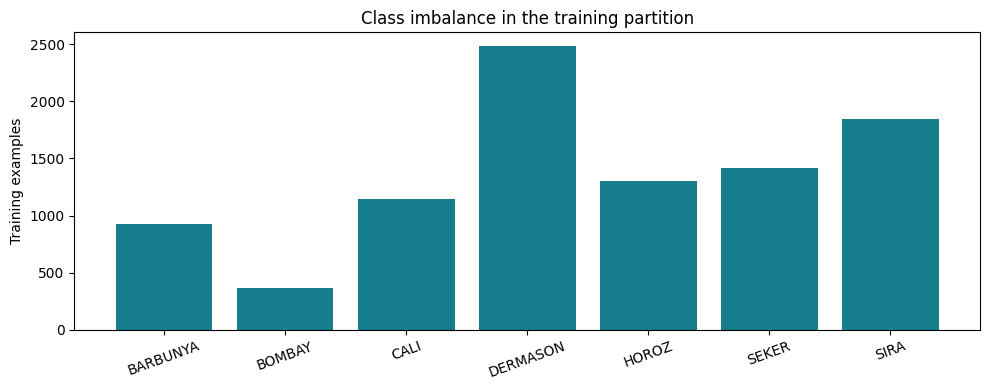

In [29]:
train_idx, holdout_idx = train_test_split(np.arange(len(data)), test_size=0.30,
    stratify=data['Class'], random_state=SPLIT_SEED)
val_idx, test_idx = train_test_split(holdout_idx, test_size=0.50,
    stratify=data.iloc[holdout_idx]['Class'], random_state=SPLIT_SEED)

assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

scaler = StandardScaler().fit(data.iloc[train_idx][features])
encoder = LabelEncoder().fit(data.iloc[train_idx]['Class'])
class_names = encoder.classes_.tolist()

def make_tensors(indices):
    x = scaler.transform(data.iloc[indices][features]).astype('float32')
    y = encoder.transform(data.iloc[indices]['Class'])
    return torch.tensor(x).to(DEVICE), torch.tensor(y, dtype=torch.long).to(DEVICE)

X_train, y_train = make_tensors(train_idx)
X_val, y_val = make_tensors(val_idx)

# Test tensors are created only after configuration selection.
class_counts = pd.DataFrame({'class':class_names,
    'train':data.iloc[train_idx]['Class'].value_counts().reindex(class_names).to_numpy(),
    'validation':data.iloc[val_idx]['Class'].value_counts().reindex(class_names).to_numpy(),
    'test':data.iloc[test_idx]['Class'].value_counts().reindex(class_names).to_numpy()})

print(class_counts.to_string(index=False))
print('Split totals:', len(train_idx), len(val_idx), len(test_idx))

class_weights = len(y_train) / (len(class_names) * torch.bincount(y_train).float())
print('Class weights:', dict(zip(class_names, class_weights.numpy().round(3).tolist())))

class_counts.to_csv(RESULTS / 'class_counts.csv', index=False)
np.savez(RESULTS / 'split_indices.npz', train=train_idx, validation=val_idx, test=test_idx)
data[['source_row','Class']].to_csv(RESULTS / 'clean_row_mapping.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_names, class_counts['train'], color='#167D8D')
ax.set(ylabel='Training examples', title='Class imbalance in the training partition')
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig(RESULTS / 'training_class_counts.png', dpi=180); plt.show()


## 3. Simple neural architectures and a linear reference
**MLP-32:** 16 inputs, Dense(32), ReLU, Dense(7). 775 trainable parameters.  
**MLP-64-32:** 16 inputs, Dense(64), ReLU, optional Dropout, Dense(32), ReLU, optional Dropout, Dense(7). 3,399 trainable parameters.

Dense parameters equal `input units × output units + output biases`. ReLU, `max(0, x)`, gives nonlinearity. Dropout has no learned parameters and turns off during evaluation. The deeper model has two hidden layers, not dozens of layers. The last layer returns **seven logits**. `CrossEntropyLoss` includes log-softmax internally, so do not add softmax before that loss. The highest logit gives the predicted class.

We also fit one multinomial logistic-regression reference with fixed `C=1.0`, standard scaling and no tuning. It helps assess whether a neural network adds value over a simpler classifier. We make no claim that it is the best possible non-neural model.


In [30]:
CONFIGS = [
    {'name':'MLP-32', 'hidden':[32], 'lr':0.001, 'dropout':0.0, 'weighted':False},
    {'name':'MLP-base', 'hidden':[64,32], 'lr':0.001, 'dropout':0.0, 'weighted':False},
    {'name':'MLP-low-lr', 'hidden':[64,32], 'lr':0.0003, 'dropout':0.0, 'weighted':False},
    {'name':'MLP-high-lr', 'hidden':[64,32], 'lr':0.003, 'dropout':0.0, 'weighted':False},
    {'name':'MLP-dropout', 'hidden':[64,32], 'lr':0.001, 'dropout':0.20, 'weighted':False},
    {'name':'MLP-weighted', 'hidden':[64,32], 'lr':0.001, 'dropout':0.0, 'weighted':True},
]

def make_model(config):
    layers, previous = [], len(features)
    for width in config['hidden']:
        layers += [nn.Linear(previous, width), nn.ReLU(), nn.Dropout(config['dropout'])]
        previous = width
    return nn.Sequential(*layers, nn.Linear(previous, len(class_names))).to(DEVICE)

for config in CONFIGS:
    model = make_model(config)
    assert model(torch.zeros(2,16)).shape == (2,7)
    print(config['name'], 'parameters:', sum(p.numel() for p in model.parameters()))

linear = LogisticRegression(C=1.0, max_iter=2000)
linear.fit(X_train.numpy(), y_train.numpy())
linear_val_pred = linear.predict(X_val.numpy())
linear_val_f1 = f1_score(y_val.numpy(), linear_val_pred, average='macro')
print('Fixed logistic reference validation macro-F1:', round(linear_val_f1, 5))


MLP-32 parameters: 775
MLP-base parameters: 3399
MLP-low-lr parameters: 3399
MLP-high-lr parameters: 3399
MLP-dropout parameters: 3399
MLP-weighted parameters: 3399
Fixed logistic reference validation macro-F1: 0.93138


## 4. Training and checkpoint selection
All neural configurations use **Adam**, **batch size 256** and **max 40 epochs**. Each runs with seeds 7, 21 and 42. CNNs are unnecessary because these inputs are named measurements, not a pixel grid.

Within each run, monitor **unweighted validation cross-entropy** and restore the lowest-loss checkpoint. Stop after eight epochs without improvement greater than 0.0001. The weighted-loss variant changes only the training loss. All validation metrics use the same unweighted definition for comparability.

For each batch: clear old gradients, compute logits and loss, backpropagate gradients, then let Adam update weights. Training and validation curves are measured after each epoch in evaluation mode, so dropout is off in both curves. Seeds control initialization and batch ordering.

**Configuration rule fixed before testing:** choose the highest mean validation macro-F1 across three seeds, then lower mean validation loss, fewer parameters and name. Keep each selected checkpoint without refitting on validation data. The seed-7 error analysis and demonstration checkpoint are fixed in advance, not chosen for test performance.


In [31]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

evaluation_loss = nn.CrossEntropyLoss()

def evaluate(model, x, y):
    model.eval()
    with torch.no_grad():
        logits = model(x)
        loss = evaluation_loss(logits, y).item()
        prediction = logits.argmax(dim=1).cpu().numpy()
    truth = y.cpu().numpy()
    return loss, accuracy_score(truth, prediction), f1_score(truth, prediction, average='macro'), prediction

def train_one(config, seed):
    set_seed(seed)
    model = make_model(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    criterion = nn.CrossEntropyLoss(weight=class_weights if config['weighted'] else None)
    loader = DataLoader(TensorDataset(X_train,y_train), batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed), num_workers=0)
    best_loss, best_state, best_epoch, stale = float('inf'), None, 0, 0
    history, started = [], time.perf_counter()

    for epoch in range(1, MAX_EPOCHS+1):

        model.train()

        for xb,yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        train_loss, train_acc, train_f1, _ = evaluate(model,X_train,y_train)
        val_loss, val_acc, val_f1, _ = evaluate(model,X_val,y_val)
        history.append({'epoch':epoch, 'train_loss':train_loss, 'val_loss':val_loss,
            'train_accuracy':train_acc, 'val_accuracy':val_acc,
            'train_macro_f1':train_f1, 'val_macro_f1':val_f1})
        
        if val_loss < best_loss - 0.0001:
            best_loss, best_epoch, stale = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())

        else:
            stale += 1

        if stale >= PATIENCE: break

    model.load_state_dict(best_state)
    val_loss, val_acc, val_f1, _ = evaluate(model,X_val,y_val)

    result = {'name':config['name'], 'seed':seed, 'val_accuracy':val_acc,
        'val_macro_f1':val_f1, 'val_loss':val_loss, 'best_epoch':best_epoch,
        'epochs_run':epoch, 'parameters':sum(p.numel() for p in model.parameters()),
        'seconds':time.perf_counter()-started}
    
    return model,pd.DataFrame(history),result

runs, models, histories = [], {}, {}
for config in CONFIGS:
    for seed in SEEDS:
        model, history, result = train_one(config,seed)
        key=(config['name'],seed)
        models[key], histories[key] = model,history
        runs.append(result)
        history.to_csv(RESULTS / f"history_{config['name']}_{seed}.csv",index=False)
        print(f"{config['name']:14s} seed={seed:2d} val F1={result['val_macro_f1']:.4f} "
              f"best epoch={result['best_epoch']:2d} time={result['seconds']:.1f}s",flush=True)
        
runs=pd.DataFrame(runs)
runs.to_csv(RESULTS/'validation_runs.csv',index=False)


MLP-32         seed= 7 val F1=0.9309 best epoch=40 time=6.3s
MLP-32         seed=21 val F1=0.9292 best epoch=40 time=5.6s
MLP-32         seed=42 val F1=0.9299 best epoch=38 time=5.1s
MLP-base       seed= 7 val F1=0.9377 best epoch=39 time=6.1s
MLP-base       seed=21 val F1=0.9348 best epoch=23 time=4.5s
MLP-base       seed=42 val F1=0.9339 best epoch=20 time=3.8s
MLP-low-lr     seed= 7 val F1=0.9306 best epoch=40 time=5.4s
MLP-low-lr     seed=21 val F1=0.9304 best epoch=40 time=5.2s
MLP-low-lr     seed=42 val F1=0.9308 best epoch=38 time=5.2s
MLP-high-lr    seed= 7 val F1=0.9375 best epoch=26 time=4.5s
MLP-high-lr    seed=21 val F1=0.9349 best epoch=13 time=2.6s
MLP-high-lr    seed=42 val F1=0.9377 best epoch=35 time=5.3s
MLP-dropout    seed= 7 val F1=0.9332 best epoch=21 time=3.9s
MLP-dropout    seed=21 val F1=0.9339 best epoch=40 time=5.6s
MLP-dropout    seed=42 val F1=0.9312 best epoch=19 time=3.8s
MLP-weighted   seed= 7 val F1=0.9364 best epoch=28 time=4.8s
MLP-weighted   seed=21 v

## 5. Validation comparison
The table shows every configuration, not just the winner. The sample standard deviation measures training-seed variability on one fixed split. It is not a confidence interval or evidence of statistical significance.

Compare MLP-32 versus MLP-base for capacity (both depth and width change). Compare each other variant against MLP-base to assess learning rate, dropout and weighted loss. Under the same epoch cap, a smaller learning rate may need more training time, so its result is also affected by convergence speed. This is a compact search, not an exhaustive optimization study.


        name  val_f1_mean  val_f1_std  val_accuracy_mean  val_accuracy_std  val_loss_mean  parameters  seconds_mean
      MLP-32      0.93000     0.00087            0.91974           0.00130        0.21739         775       5.66912
    MLP-base      0.93548     0.00202            0.92647           0.00233        0.20619        3399       4.80443
  MLP-low-lr      0.93061     0.00018            0.92073           0.00049        0.21598        3399       5.26639
 MLP-high-lr      0.93672     0.00154            0.92779           0.00271        0.20247        3399       4.12877
 MLP-dropout      0.93280     0.00139            0.92319           0.00130        0.21204        3399       4.42647
MLP-weighted      0.93523     0.00105            0.92598           0.00124        0.20943        3399       4.80670
Validation-selected neural configuration: MLP-high-lr
Logistic reference validation macro-F1: 0.93138


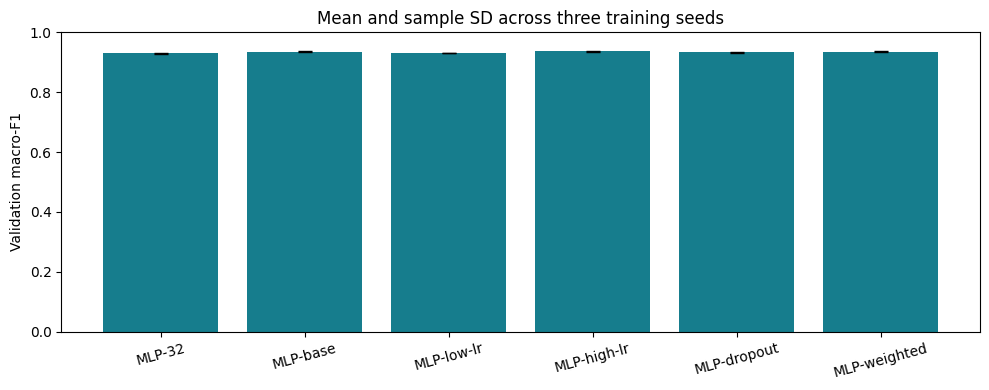

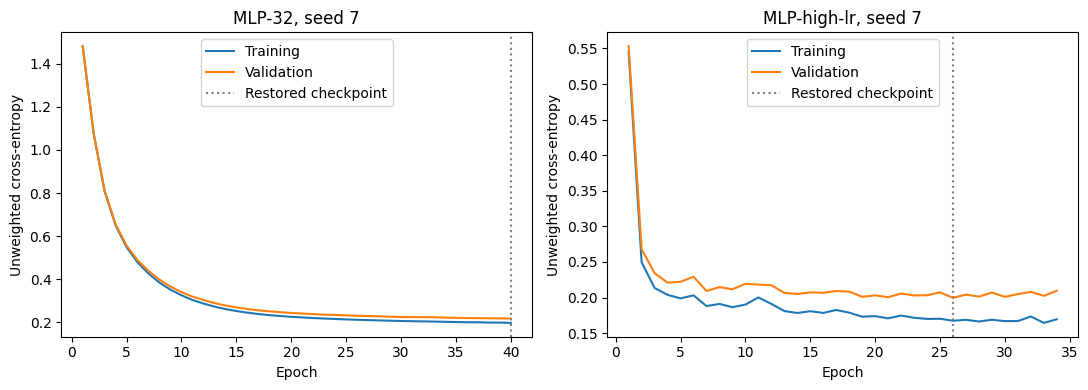

        name  seed  epoch  train_loss  val_loss
      MLP-32     7     40     0.19746   0.21756
      MLP-32    21     40     0.19688   0.21866
      MLP-32    42     40     0.19736   0.21631
    MLP-base     7     40     0.17470   0.20346
    MLP-base    21     31     0.17996   0.20881
    MLP-base    42     28     0.18265   0.20996
  MLP-low-lr     7     40     0.19649   0.21695
  MLP-low-lr    21     40     0.19964   0.21442
  MLP-low-lr    42     40     0.19638   0.21680
 MLP-high-lr     7     34     0.16941   0.20957
 MLP-high-lr    21     21     0.17663   0.20743
 MLP-high-lr    42     40     0.16413   0.21165
 MLP-dropout     7     29     0.18745   0.21405
 MLP-dropout    21     40     0.18155   0.20747
 MLP-dropout    42     27     0.19041   0.21704
MLP-weighted     7     36     0.18273   0.20951
MLP-weighted    21     31     0.18329   0.21189
MLP-weighted    42     40     0.18555   0.21758
        name  train_loss_mean  train_loss_std  val_loss_mean  val_loss_std
      MLP-32 

In [38]:
summary=runs.groupby('name',sort=False).agg(
    val_f1_mean=('val_macro_f1','mean'),val_f1_std=('val_macro_f1','std'),
    val_accuracy_mean=('val_accuracy','mean'),val_accuracy_std=('val_accuracy','std'),
    val_loss_mean=('val_loss','mean'),parameters=('parameters','first'),
    seconds_mean=('seconds','mean')).reset_index()

ranking=summary.sort_values(['val_f1_mean','val_loss_mean','parameters','name'],
                            ascending=[False,True,True,True])

selected_name=ranking.iloc[0]['name']
selected_config=next(c for c in CONFIGS if c['name']==selected_name)

print(summary.round(5).to_string(index=False))
print('Validation-selected neural configuration:',selected_name)
print('Logistic reference validation macro-F1:',round(linear_val_f1,5))

summary.to_csv(RESULTS/'validation_summary.csv',index=False)

fig,ax=plt.subplots(figsize=(10,4))
ax.bar(summary['name'],summary.val_f1_mean,yerr=summary.val_f1_std,capsize=5,color='#167D8D')
ax.set(ylim=(0,1),ylabel='Validation macro-F1',title='Mean and sample SD across three training seeds')
plt.xticks(rotation=15);plt.tight_layout()
plt.savefig(RESULTS/'validation_comparison.png',dpi=180);plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))

for name,ax in zip(['MLP-32',selected_name],axes):
    history=histories[(name,7)]

    ax.plot(history.epoch,history.train_loss,label='Training')
    ax.plot(history.epoch,history.val_loss,label='Validation')

    best=int(runs[(runs.name==name)&(runs.seed==7)].iloc[0].best_epoch)
    ax.axvline(best,color='gray',linestyle=':',label='Restored checkpoint')
    ax.set(title=f'{name}, seed 7',xlabel='Epoch',ylabel='Unweighted cross-entropy');ax.legend()

plt.tight_layout();plt.savefig(RESULTS/'learning_curves.png',dpi=180);plt.show()
end_loss_rows = []

for config in CONFIGS:
    for seed in SEEDS:
        final_epoch = histories[(config['name'], seed)].iloc[-1]
        end_loss_rows.append({
            'name': config['name'],
            'seed': seed,
            'epoch': int(final_epoch['epoch']),
            'train_loss': final_epoch['train_loss'],
            'val_loss': final_epoch['val_loss']
        })

end_loss = pd.DataFrame(end_loss_rows)

end_loss_summary = end_loss.groupby('name', sort=False).agg(
    train_loss_mean=('train_loss', 'mean'),
    train_loss_std=('train_loss', 'std'),
    val_loss_mean=('val_loss', 'mean'),
    val_loss_std=('val_loss', 'std')
).reset_index()

print(end_loss.round(5).to_string(index=False))
print(end_loss_summary.round(5).to_string(index=False))

end_loss.to_csv(RESULTS / 'final_epoch_losses.csv', index=False)
end_loss_summary.to_csv(RESULTS / 'final_epoch_loss_summary.csv', index=False)


## 6. One final test stage
We now evaluate the validation-selected neural configuration, the prespecified small MLP baseline and the fixed logistic-regression reference. No other neural candidates receive test scores. All three neural seeds are retained, with no test-based seed selection and no ensemble. The logistic reference is one deterministic fit, so it has no three-seed standard deviation.

Do not choose a new neural configuration or alter hyperparameters after viewing test results. Any additional tuning should use development data, with new independent data for a fresh final confirmation.


In [33]:
X_test,y_test=make_tensors(test_idx)

test_rows=[]

for name in dict.fromkeys(['MLP-32',selected_name]):
    for seed in SEEDS:
        loss,acc,f1,pred=evaluate(models[(name,seed)],X_test,y_test)
        test_rows.append({'name':name,'seed':seed,'test_accuracy':acc,'test_macro_f1':f1,'test_loss':loss})

test_runs=pd.DataFrame(test_rows)
test_summary=test_runs.groupby('name',sort=False).agg(
    accuracy_mean=('test_accuracy','mean'),accuracy_std=('test_accuracy','std'),
    macro_f1_mean=('test_macro_f1','mean'),macro_f1_std=('test_macro_f1','std')).reset_index()

linear_pred=linear.predict(X_test.numpy())
linear_result={'name':'Logistic regression','val_macro_f1':linear_val_f1,
    'test_accuracy':accuracy_score(y_test.numpy(),linear_pred),
    'test_macro_f1':f1_score(y_test.numpy(),linear_pred,average='macro')}

print(test_runs.round(5).to_string(index=False))
print('Neural test summaries:');print(test_summary.round(5).to_string(index=False))
print('Fixed linear reference:',linear_result)

test_runs.to_csv(RESULTS/'test_runs.csv',index=False)
test_summary.to_csv(RESULTS/'test_summary.csv',index=False)
(RESULTS/'logistic_reference.json').write_text(json.dumps(linear_result,indent=2))


       name  seed  test_accuracy  test_macro_f1  test_loss
     MLP-32     7        0.92077        0.93326    0.21599
     MLP-32    21        0.92126        0.93403    0.21647
     MLP-32    42        0.91880        0.93187    0.21835
MLP-high-lr     7        0.92470        0.93766    0.21407
MLP-high-lr    21        0.92274        0.93527    0.20615
MLP-high-lr    42        0.92569        0.93902    0.20749
Neural test summaries:
       name  accuracy_mean  accuracy_std  macro_f1_mean  macro_f1_std
     MLP-32        0.92028        0.0013        0.93305       0.00109
MLP-high-lr        0.92438        0.0015        0.93732       0.00190
Fixed linear reference: {'name': 'Logistic regression', 'val_macro_f1': 0.9313788167940461, 'test_accuracy': 0.921751968503937, 'test_macro_f1': 0.934867494254538}


149

## 7. Per-class results and errors
The confusion matrix uses true classes in rows and predicted classes in columns. Its diagonal counts are correct classifications. We display the selected neural model with seed 7, fixed in advance. This is not the same as the three-seed average.

The error table records source rows, true/predicted labels and selected raw feature values. These are tabular measurements, so there are no original bean photographs to display. Similar measurements may help explain a confusion, but a feature table alone does not establish the network's causal reasoning.


              precision    recall  f1-score   support

    BARBUNYA     0.9257    0.9444    0.9350       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9498    0.9265    0.9380       245
    DERMASON     0.9229    0.9004    0.9115       532
       HOROZ     0.9466    0.9534    0.9500       279
       SEKER     0.9542    0.9605    0.9574       304
        SIRA     0.8600    0.8838    0.8717       396

    accuracy                         0.9247      2032
   macro avg     0.9370    0.9384    0.9377      2032
weighted avg     0.9251    0.9247    0.9248      2032

Seed 7 mistakes: 153 / 2032
First ten mistakes in test-partition order:
 clean_row  source_row     true predicted    Area  AspectRation  Compactness
     13395       13463 DERMASON      SIRA 40358.0      1.393405     0.845594
     12411       12479 DERMASON      SIRA 34518.0      1.647574     0.776206
      7446        7514     SIRA  DERMASON 36606.0      1.332342     0.862408
      7218        7283 

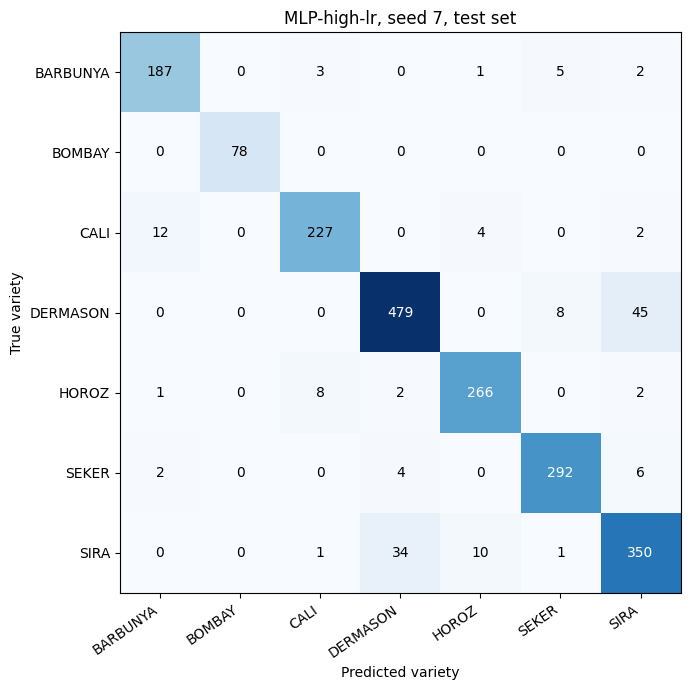

In [34]:
final_model = models[(selected_name, 7)]
_, example_acc, example_f1, prediction = evaluate(final_model, X_test, y_test)

cm = confusion_matrix(y_test.numpy(), prediction, labels=range(7))
report = classification_report(
    y_test.numpy(),
    prediction,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print(classification_report(
    y_test.numpy(),
    prediction,
    target_names=class_names,
    digits=4,
    zero_division=0
))

errors = np.flatnonzero(prediction != y_test.numpy())
print(f"Seed 7 mistakes: {len(errors)} / {len(y_test)}")

predictions = pd.DataFrame({
    'clean_row': test_idx,
    'source_row': data.iloc[test_idx].source_row.to_numpy(),
    'true': encoder.inverse_transform(y_test.numpy()),
    'predicted': encoder.inverse_transform(prediction)
})
predictions.to_csv(RESULTS / 'predictions_seed7.csv', index=False)

error_examples = predictions.iloc[errors[:10]].copy()

for feature in ['Area', 'AspectRation', 'Compactness']:
    error_examples[feature] = data.iloc[test_idx[errors[:10]]][feature].to_numpy()

print('First ten mistakes in test-partition order:')
print(error_examples.to_string(index=False))

error_examples.to_csv(RESULTS / 'error_examples.csv', index=False)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    RESULTS / 'confusion_matrix_seed7.csv'
)
pd.DataFrame(report).T.to_csv(RESULTS / 'classification_report_seed7.csv')

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(cm, cmap='Blues')

for i in range(7):
    for j in range(7):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha='center',
            va='center',
            color='white' if cm[i, j] > cm.max() / 2 else 'black'
        )

ax.set(
    xticks=range(7),
    yticks=range(7),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel='Predicted variety',
    ylabel='True variety',
    title=f'{selected_name}, seed 7, test set'
)

plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(RESULTS / 'confusion_matrix.png', dpi=180)
plt.show()


## 8. Save preprocessing with the model and verify reloading
The saved model is useful only with the same feature order, training means/scales and label mapping. The checkpoint stores those values with the architecture and weights. For new beans, provide 16 features extracted in the same way. A photograph cannot be passed directly to this network.


In [35]:
# Save the selected model and preprocessing information.
checkpoint = {
    'config': selected_config,
    'state_dict': final_model.state_dict(),
    'seed': 7,
    'features': features,
    'classes': class_names,
    'mean': scaler.mean_.tolist(),
    'scale': scaler.scale_.tolist()
}

model_path = RESULTS / 'selected_model_seed7.pt'
torch.save(checkpoint, model_path)

# Reload the model and verify that its predictions are unchanged.
saved = torch.load(model_path, map_location=DEVICE, weights_only=True)

reloaded = make_model(saved['config'])
reloaded.load_state_dict(saved['state_dict'])
reloaded.eval()

raw_examples = data.iloc[test_idx[:10]][saved['features']].to_numpy()
scaled_examples = (
    raw_examples - np.array(saved['mean'])
) / np.array(saved['scale'])

with torch.no_grad():
    logits = reloaded(torch.tensor(scaled_examples, dtype=torch.float32))
    original_logits = final_model(X_test[:10])

    assert torch.allclose(logits, original_logits, atol=1e-6)

    probabilities = torch.softmax(logits[0], dim=0)
    predicted_index = probabilities.argmax().item()

print('Reload verified. True class:', class_names[y_test[0].item()])
print(
    'Predicted class:',
    class_names[predicted_index],
    'Softmax confidence:',
    round(probabilities.max().item(), 4)
)

# Save experiment metadata for reproducibility.
metadata = {
    'dataset_url': DATA_URL,
    'dataset_sha256': data_hash,
    'versions': versions,
    'raw_rows': len(raw),
    'duplicates_removed': removed,
    'clean_rows': len(data),
    'training_examples': len(train_idx),
    'validation_examples': len(val_idx),
    'test_examples': len(test_idx),
    'split_seed': SPLIT_SEED,
    'seeds': SEEDS,
    'configs': CONFIGS,
    'selected_config': selected_config,
    'max_epochs': MAX_EPOCHS,
    'patience': PATIENCE,
    'batch_size': BATCH_SIZE,
    'features': features,
    'classes': class_names,
    'example_seed': 7,
    'example_errors': len(errors),
    'example_accuracy': example_acc,
    'example_macro_f1': example_f1
}

metadata_path = RESULTS / 'experiment_metadata.json'
metadata_path.write_text(json.dumps(metadata, indent=2))

print('Artifacts saved in:', RESULTS.resolve())


Reload verified. True class: DERMASON
Predicted class: DERMASON Softmax confidence: 0.9937
Artifacts saved in: C:\Users\edgar\OneDrive\Documents\IMT Atlantique\TC Gadjah Mada\Advanced Deep Learning\DeepLearning_miniproject\results


### Selected algorithm

In [36]:
selected_test=test_summary.set_index('name').loc[selected_name]
baseline_test=test_summary.set_index('name').loc['MLP-32']
print('Selected configuration:',selected_name)
print(f"Mean test macro-F1: {selected_test.macro_f1_mean:.4f}")
print(f"Mean test accuracy: {100*selected_test.accuracy_mean:.2f}%")
print(f"Macro-F1 difference versus MLP-32: {selected_test.macro_f1_mean-baseline_test.macro_f1_mean:+.4f}")
print(f"Fixed logistic reference test macro-F1: {linear_result['test_macro_f1']:.4f}")
import shutil
bundle=shutil.make_archive('drybean_results','zip',RESULTS)
print('Results ZIP:',bundle)
# In Colab, uncomment these two lines to download all results.
# from google.colab import files
# files.download(bundle)


Selected configuration: MLP-high-lr
Mean test macro-F1: 0.9373
Mean test accuracy: 92.44%
Macro-F1 difference versus MLP-32: +0.0043
Fixed logistic reference test macro-F1: 0.9349
Results ZIP: c:\Users\edgar\OneDrive\Documents\IMT Atlantique\TC Gadjah Mada\Advanced Deep Learning\DeepLearning_miniproject\drybean_results.zip


## 9. Interpretation and limitations

Based on our tests, the best algorithm is **MLP-high-lr**, a neural network with two hidden layers (64 and 32 units) and a learning rate of 0.003. It achieved the highest validation macro-F1 (**0.9367**) and a mean test macro-F1 of **0.9373** across three seeds, outperforming the MLP-32 baseline (**0.9331**) and the logistic-regression reference (**0.9349**). The results suggest that the deeper architecture and higher learning rate improved classification, although the modest differences should not be interpreted as statistically significant.

Removing exact duplicate rows prevents one obvious source of optimistic evaluation. It does not guarantee independence between acquisition batches. Random splits estimate performance under a similar data distribution, not transfer to new farms, harvests, cameras or measurement pipelines. No batch/farm identifiers are available in these files. Test scores cannot establish a deployable sorting system.

The next step is repeated development splits and an independent dataset from a different acquisition session. Additional capacity should respond to evidence of underfitting rather than be added merely because the course concerns deep learning.

### References
1. Dry Bean (2020), UCI Machine Learning Repository. https://doi.org/10.24432/C50S4B
2. PyTorch, CrossEntropyLoss. https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
3. PyTorch, Reproducibility. https://docs.pytorch.org/docs/stable/notes/randomness.html
4. scikit-learn, StandardScaler. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
